# Explainable AI for Credit Risk Assessment

Computer Science Project, predicting serious delinquency within two years using Logistic Regression, Random Forest and XGBoost, with SHAP and LIME based interpretability

## 1. Environment Setup and Library Installation

In [1]:
!pip install xgboost shap lime --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
# importing core libraries for data handling and computation
import numpy as np
import pandas as pd

# importing visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# importing preprocessing and modelling utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# importing evaluation metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve, confusion_matrix,
                              classification_report)

# importing explainability libraries
import shap
import lime
import lime.lime_tabular

# setting global plot style for consistent visuals
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# setting random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# silencing warnings for a cleaner notebook output
import warnings
warnings.filterwarnings("ignore")


## 2. Dataset Acquisition

In [3]:
# loading the credit risk benchmark dataset into a dataframe
df = pd.read_csv("/content/Credit Risk Benchmark Dataset.csv")
df.shape


(16714, 11)

## 3. Dataset Overview and Descriptive Statistics

In [4]:
# viewing the first few records of the dataset
df.head()


,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents,dlq_2yrs
0,0.006999,38.0,0.0,0.302150,5440.0,4.0,0.0,1.0,0.0,3.0,0
1,0.704592,63.0,0.0,0.471441,8000.0,9.0,0.0,1.0,0.0,0.0,0
2,0.063113,57.0,0.0,0.068586,5000.0,17.0,0.0,0.0,0.0,0.0,0
3,0.368397,68.0,0.0,0.296273,6250.0,16.0,0.0,2.0,0.0,0.0,0
4,1.000000,34.0,1.0,0.000000,3500.0,0.0,0.0,0.0,0.0,1.0,0


In [5]:
# checking column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16714 entries, 0 to 16713
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rev_util     16714 non-null  float64
 1   age          16714 non-null  float64
 2   late_30_59   16714 non-null  float64
 3   debt_ratio   16714 non-null  float64
 4   monthly_inc  16714 non-null  float64
 5   open_credit  16714 non-null  float64
 6   late_90      16714 non-null  float64
 7   real_estate  16714 non-null  float64
 8   late_60_89   16714 non-null  float64
 9   dependents   16714 non-null  float64
 10  dlq_2yrs     16714 non-null  int64  
dtypes: float64(10), int64(1)
memory usage: 1.4 MB


In [6]:
# generating descriptive statistics for all numerical predictors
df.describe().T


,count,mean,std,min,25%,50%,75%,max
rev_util,16714.0,4.799862,204.062345,0.0,0.082397,0.443080,0.926637,22000.0
age,16714.0,48.798672,13.906078,21.0,38.000000,48.000000,58.000000,101.0
late_30_59,16714.0,1.110267,7.172890,0.0,0.000000,0.000000,1.000000,98.0
debt_ratio,16714.0,30.980298,719.694859,0.0,0.155971,0.322299,0.533426,61106.5
monthly_inc,16714.0,6118.120258,5931.841779,0.0,3128.500000,5000.000000,7573.000000,250000.0
open_credit,16714.0,8.503709,5.370965,0.0,5.000000,8.000000,11.000000,57.0
late_90,16714.0,0.863827,7.167576,0.0,0.000000,0.000000,0.000000,98.0
real_estate,16714.0,1.047445,1.272565,0.0,0.000000,1.000000,2.000000,29.0
late_60_89,16714.0,0.734354,7.138737,0.0,0.000000,0.000000,0.000000,98.0
dependents,16714.0,0.944358,1.198791,0.0,0.000000,0.000000,2.000000,8.0


In [7]:
# checking the number of duplicate records present in the dataset
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows found:", duplicate_count)


Number of duplicate rows found: 2


## 4. Missing Value Analysis

In [8]:
# counting missing values for every column in the dataset
missing_summary = df.isnull().sum().to_frame("missing_count")
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df)) * 100
missing_summary


,missing_count,missing_percent
rev_util,0,0.0
age,0,0.0
late_30_59,0,0.0
debt_ratio,0,0.0
monthly_inc,0,0.0
open_credit,0,0.0
late_90,0,0.0
real_estate,0,0.0
late_60_89,0,0.0
dependents,0,0.0


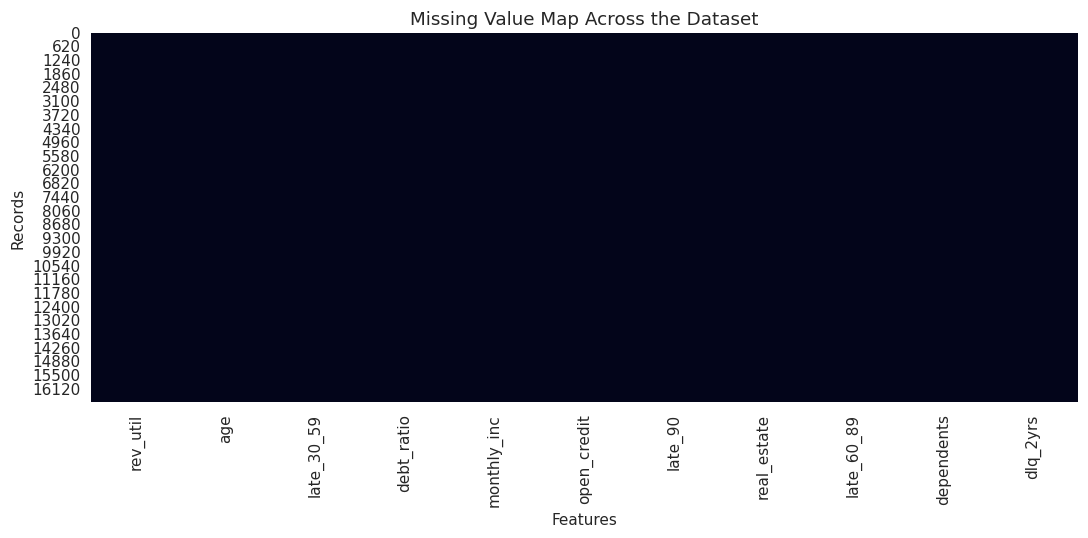

In [9]:
# visualising missing values across the dataset using a heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="rocket")
plt.title("Missing Value Map Across the Dataset")
plt.xlabel("Features")
plt.ylabel("Records")
plt.tight_layout()
plt.show()


## 5. Data Cleaning and Outlier Treatment

The delinquency counters contain sentinel codes of 96 and 98 which are data entry artefacts rather than genuine counts, so these are being capped to the next highest realistic value before modelling

In [10]:
# dropping exact duplicate rows from the dataset
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)


Shape after removing duplicates: (16712, 11)


In [11]:
# inspecting the delinquency counters for unrealistic sentinel values such as 96 and 98
late_columns = ["late_30_59", "late_90", "late_60_89"]
for col in late_columns:
    print(col, "unique high values:", sorted(df[col].unique())[-5:])


late_30_59 unique high values: [np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(96.0), np.float64(98.0)]
late_90 unique high values: [np.float64(13.0), np.float64(14.0), np.float64(17.0), np.float64(96.0), np.float64(98.0)]
late_60_89 unique high values: [np.float64(7.0), np.float64(8.0), np.float64(11.0), np.float64(96.0), np.float64(98.0)]


In [12]:
# capping the sentinel codes in the delinquency counters to a realistic upper bound
for col in late_columns:
    cap_value = df.loc[df[col] < 90, col].max()
    df[col] = np.where(df[col] >= 90, cap_value, df[col])

print("Maximum values after capping the sentinel codes:")
print(df[late_columns].max())


Maximum values after capping the sentinel codes:
late_30_59    13.0
late_90       17.0
late_60_89    11.0
dtype: float64


In [13]:
# capping extreme outliers in revolving utilisation and debt ratio at the 99th percentile
for col in ["rev_util", "debt_ratio"]:
    upper_limit = df[col].quantile(0.99)
    df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])

df[["rev_util", "debt_ratio"]].describe().T


,count,mean,std,min,25%,50%,75%,max
rev_util,16712.0,0.498700,0.406431,0.0,0.082360,0.442986,0.926588,1.447604
debt_ratio,16712.0,4.528466,37.605482,0.0,0.156079,0.322318,0.533458,368.140000


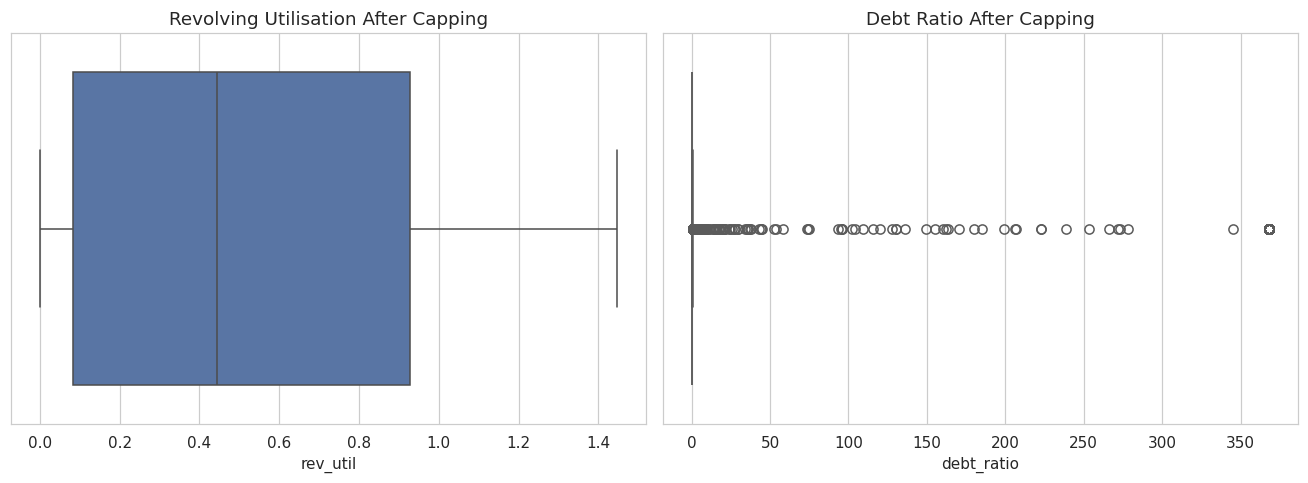

In [14]:
# comparing the distribution of revolving utilisation before and after capping outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(x=df["rev_util"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Revolving Utilisation After Capping")

sns.boxplot(x=df["debt_ratio"], ax=axes[1], color="#DD8452")
axes[1].set_title("Debt Ratio After Capping")

plt.tight_layout()
plt.show()


## 6. Exploratory Data Analysis

### 6.1 Target Class Distribution

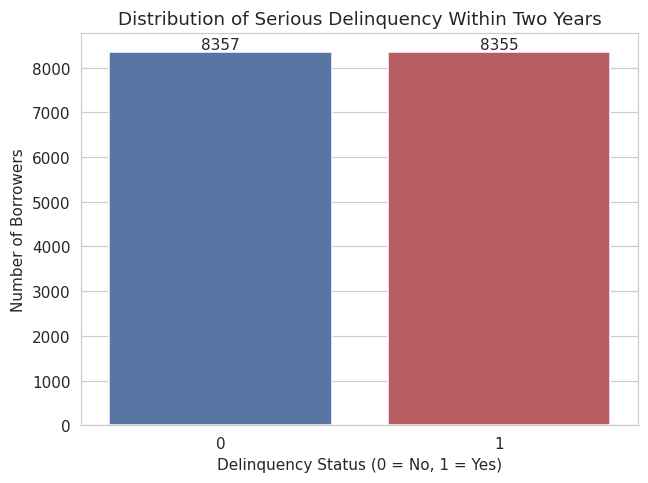

dlq_2yrs
0    0.50006
1    0.49994
Name: proportion, dtype: float64


In [15]:
# visualising the distribution of the target variable
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(x="dlq_2yrs", data=df, hue="dlq_2yrs", palette=["#4C72B0", "#C44E52"], legend=False)
ax.set_title("Distribution of Serious Delinquency Within Two Years")
ax.set_xlabel("Delinquency Status (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Borrowers")

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

print(df["dlq_2yrs"].value_counts(normalize=True).rename("proportion"))


### 6.2 Feature Distributions by Delinquency Status

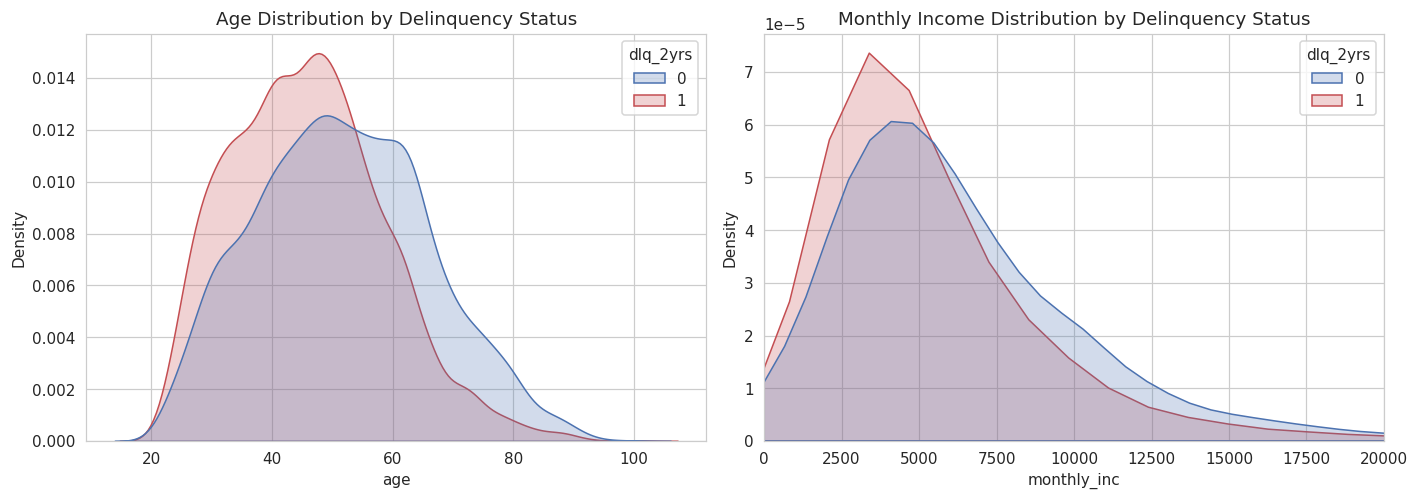

In [16]:
# comparing the age and monthly income distributions across delinquency status
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.kdeplot(data=df, x="age", hue="dlq_2yrs", fill=True, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Age Distribution by Delinquency Status")

sns.kdeplot(data=df, x="monthly_inc", hue="dlq_2yrs", fill=True, ax=axes[1], palette=["#4C72B0", "#C44E52"])
axes[1].set_xlim(0, 20000)
axes[1].set_title("Monthly Income Distribution by Delinquency Status")

plt.tight_layout()
plt.show()


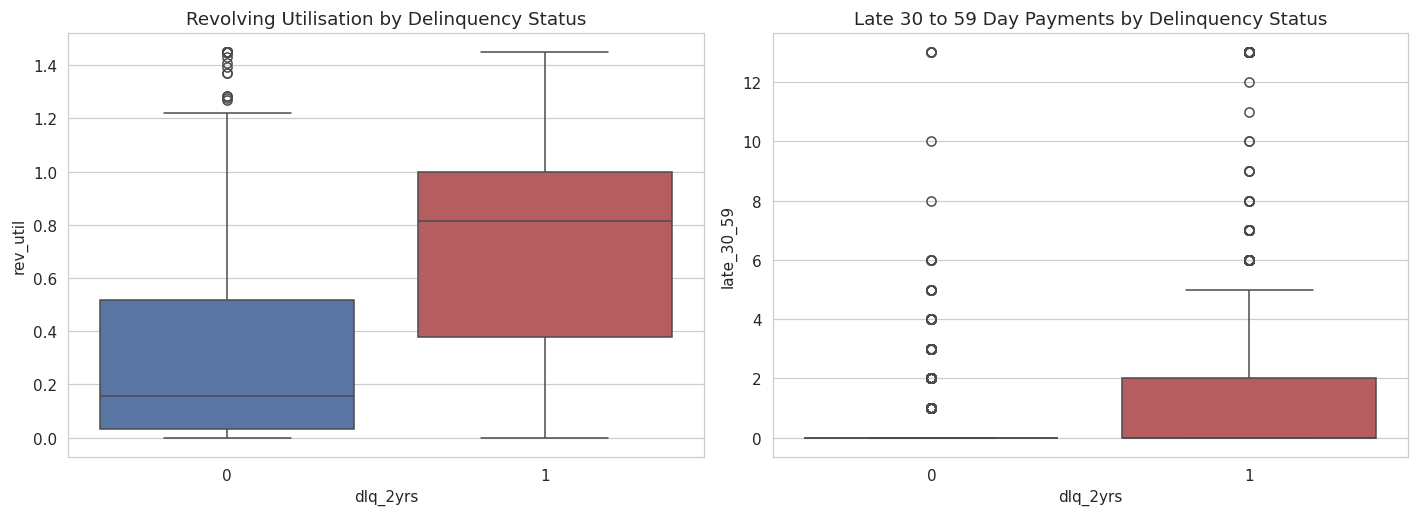

In [17]:
# comparing revolving utilisation and number of late 30 to 59 day payments across delinquency status
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.boxplot(data=df, x="dlq_2yrs", y="rev_util", hue="dlq_2yrs", palette=["#4C72B0", "#C44E52"], legend=False, ax=axes[0])
axes[0].set_title("Revolving Utilisation by Delinquency Status")

sns.boxplot(data=df, x="dlq_2yrs", y="late_30_59", hue="dlq_2yrs", palette=["#4C72B0", "#C44E52"], legend=False, ax=axes[1])
axes[1].set_title("Late 30 to 59 Day Payments by Delinquency Status")

plt.tight_layout()
plt.show()


### 6.3 Feature Correlation Heatmap

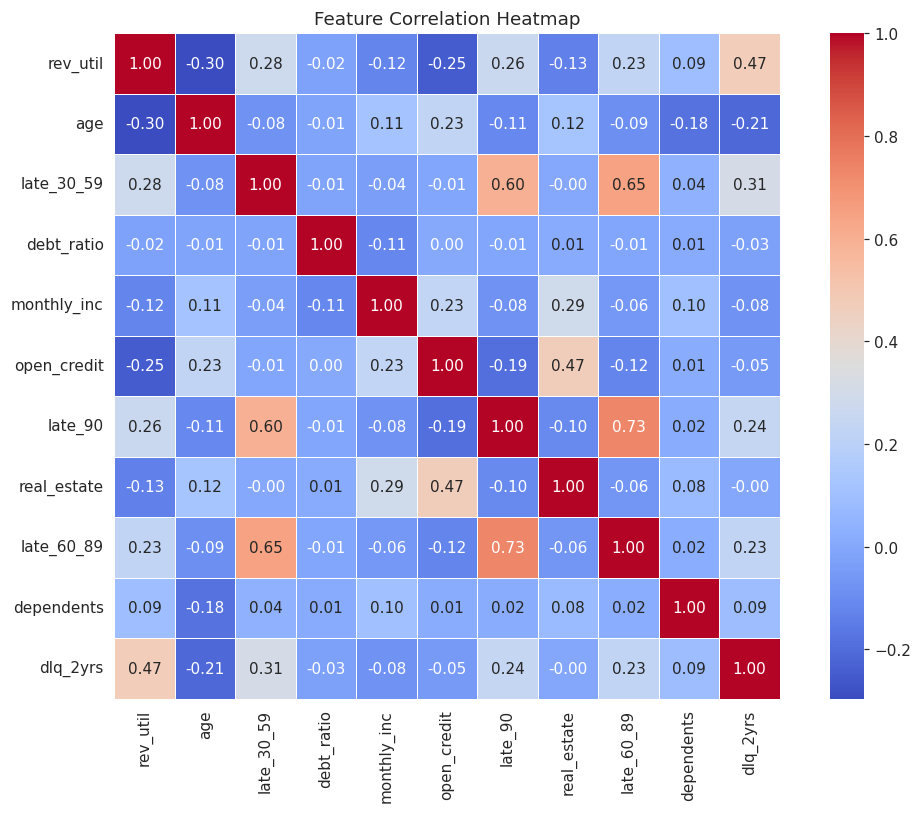

In [18]:
# plotting a correlation heatmap across all numerical features
plt.figure(figsize=(10, 7.5))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## 7. Feature Preparation

In [19]:
# separating predictor features from the target variable
X = df.drop(columns=["dlq_2yrs"])
y = df["dlq_2yrs"]

feature_names = X.columns.tolist()
print("Predictor features being used:", feature_names)


Predictor features being used: ['rev_util', 'age', 'late_30_59', 'debt_ratio', 'monthly_inc', 'open_credit', 'late_90', 'real_estate', 'late_60_89', 'dependents']


## 8. Train Test Split

In [20]:
# splitting the dataset into training and testing sets using stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (13369, 10)
Testing set shape: (3343, 10)


In [21]:
# scaling the features so that logistic regression coefficients remain comparable
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)

X_train_scaled.head()


,rev_util,age,late_30_59,debt_ratio,monthly_inc,open_credit,late_90,real_estate,late_60_89,dependents
16193,-0.409341,0.164578,2.298749,-0.112346,-0.171496,-1.021531,-0.277166,-0.038600,0.723316,0.047338
14522,-0.153160,1.030419,-0.456432,-0.088344,-0.720385,0.832331,-0.277166,0.762707,-0.267972,0.047338
8273,-0.605351,-1.062030,-0.456432,-0.115856,0.046041,-0.094600,-0.277166,-0.839907,-0.267972,-0.788675
1197,2.336463,-0.412649,-0.456432,-0.117269,-0.650077,-1.392304,-0.277166,-0.839907,-0.267972,-0.788675
6409,1.235763,-0.556956,-0.456432,-0.108313,-0.420706,-0.836145,-0.277166,-0.038600,-0.267972,0.047338


## 9. Model Training

### 9.1 Logistic Regression

In [22]:
# training a logistic regression model on the scaled features
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

log_reg_pred = log_reg.predict(X_test_scaled)
log_reg_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
print("Logistic Regression training is complete")


Logistic Regression training is complete


### 9.2 Random Forest

In [23]:
# training a random forest classifier on the original unscaled features
rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=5,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]
print("Random Forest training is complete")


Random Forest training is complete


### 9.3 XGBoost

In [24]:
# training an xgboost classifier on the original unscaled features
xgb_model = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.08,
    subsample=0.9, colsample_bytree=0.9,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
)
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]
print("XGBoost training is complete")


XGBoost training is complete


## 10. Performance Evaluation and Comparison

### 10.1 Model Performance Comparison Table

In [25]:
# building a helper function that computes all the required evaluation metrics
def evaluate_model(name, y_true, y_pred, y_proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_proba)
    }

results = [
    evaluate_model("Logistic Regression", y_test, log_reg_pred, log_reg_proba),
    evaluate_model("Random Forest", y_test, rf_pred, rf_proba),
    evaluate_model("XGBoost", y_test, xgb_pred, xgb_proba),
]

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Logistic Regression,0.7676,0.7829,0.7403,0.7610,0.8504
Random Forest,0.7783,0.7832,0.7696,0.7763,0.8587
XGBoost,0.7739,0.7868,0.7510,0.7685,0.8576


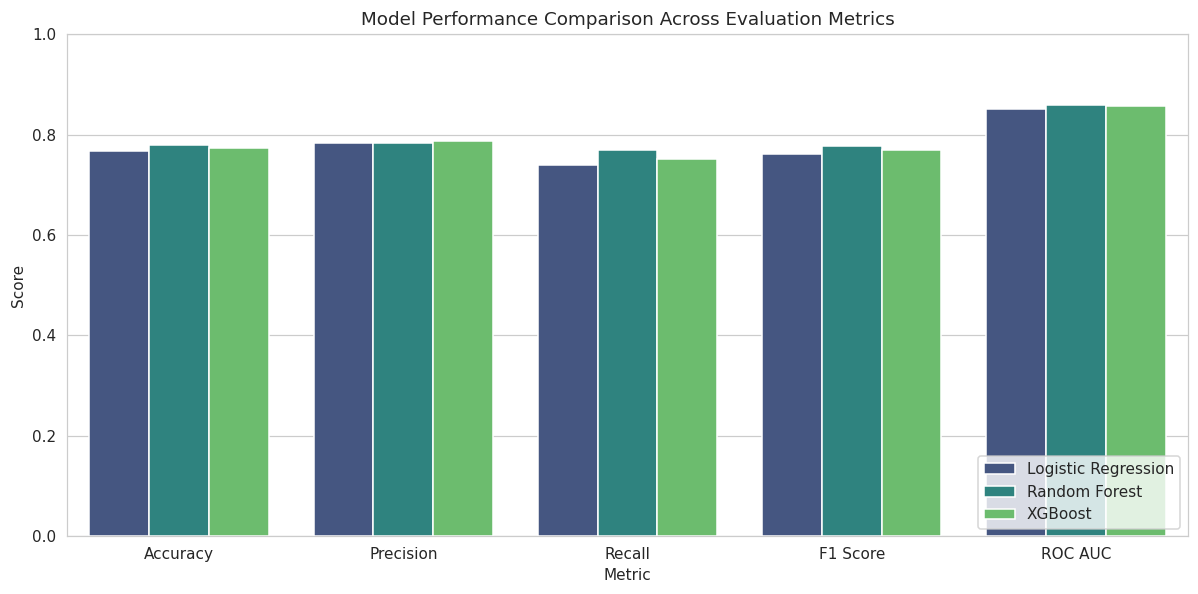

In [26]:
# visualising the comparison of the key metrics across all three models
plot_df = results_df.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(11, 5.5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="viridis")
plt.title("Model Performance Comparison Across Evaluation Metrics")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 10.2 Classification Reports

In [27]:
# printing detailed classification reports for every model
for name, pred in [("Logistic Regression", log_reg_pred), ("Random Forest", rf_pred), ("XGBoost", xgb_pred)]:
    print(f"Classification report for {name}")
    print(classification_report(y_test, pred))
    print("")


Classification report for Logistic Regression
              precision    recall  f1-score   support

           0       0.75      0.79      0.77      1672
           1       0.78      0.74      0.76      1671

    accuracy                           0.77      3343
   macro avg       0.77      0.77      0.77      3343
weighted avg       0.77      0.77      0.77      3343


Classification report for Random Forest
              precision    recall  f1-score   support

           0       0.77      0.79      0.78      1672
           1       0.78      0.77      0.78      1671

    accuracy                           0.78      3343
   macro avg       0.78      0.78      0.78      3343
weighted avg       0.78      0.78      0.78      3343


Classification report for XGBoost
              precision    recall  f1-score   support

           0       0.76      0.80      0.78      1672
           1       0.79      0.75      0.77      1671

    accuracy                           0.77      3343
   mac

### 10.3 Confusion Matrices

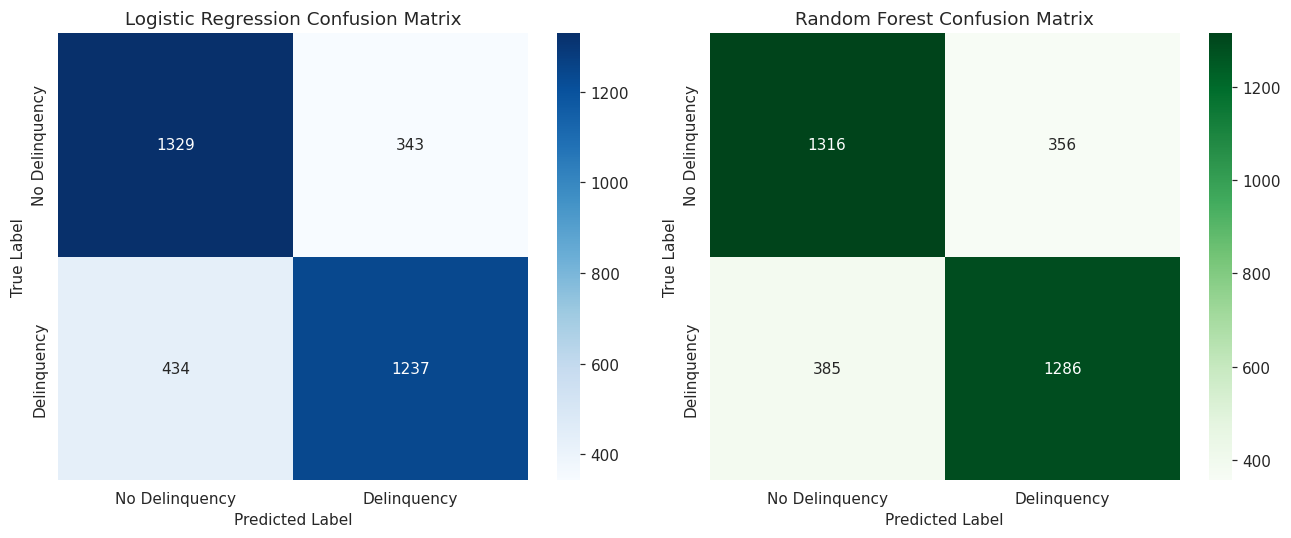

In [28]:
# plotting confusion matrices for logistic regression and random forest
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, log_reg_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No Delinquency", "Delinquency"], yticklabels=["No Delinquency", "Delinquency"])
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["No Delinquency", "Delinquency"], yticklabels=["No Delinquency", "Delinquency"])
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()


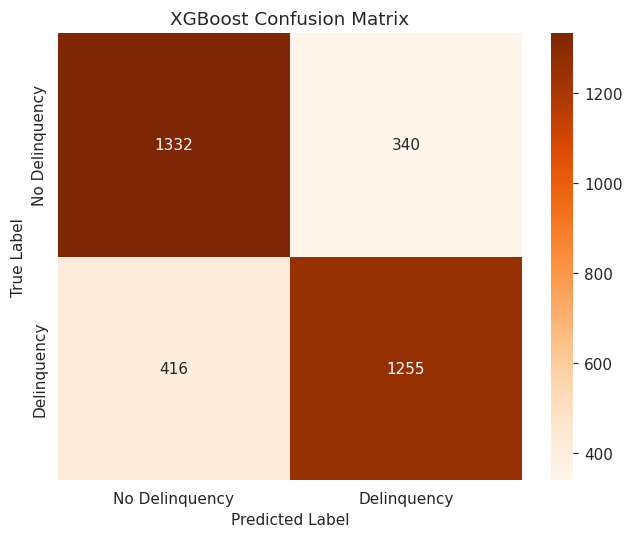

In [29]:
# plotting the confusion matrix for xgboost
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt="d", cmap="Oranges",
            xticklabels=["No Delinquency", "Delinquency"], yticklabels=["No Delinquency", "Delinquency"])
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


### 10.4 ROC Curves

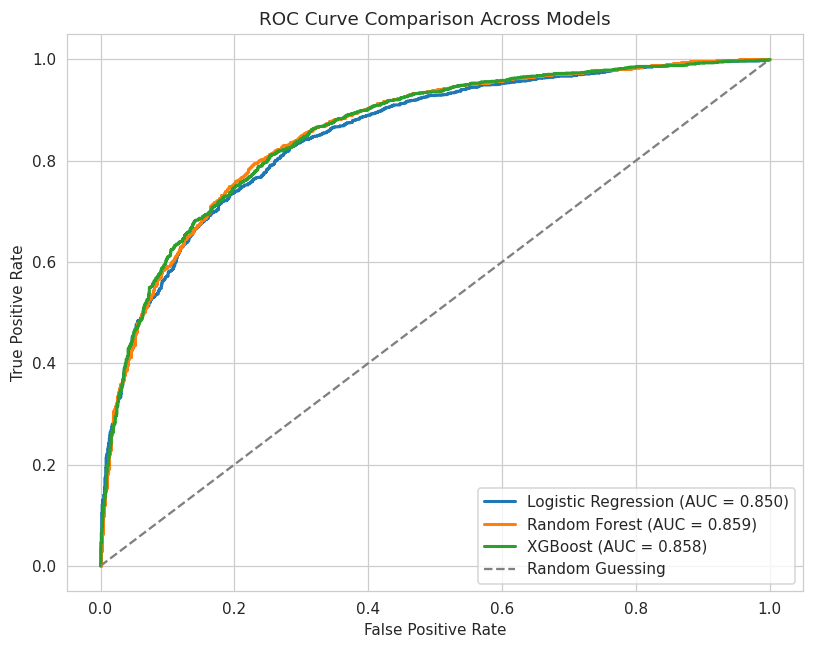

In [30]:
# plotting roc curves for all three models on the same axes for direct comparison
plt.figure(figsize=(7.5, 6))

for name, proba in [("Logistic Regression", log_reg_proba), ("Random Forest", rf_proba), ("XGBoost", xgb_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_score = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random Guessing")
plt.title("ROC Curve Comparison Across Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 11. Selection of the Best Performing Model

In [31]:
# selecting the best performing model based on roc auc score
best_model_name = results_df["ROC AUC"].idxmax()
print("The best performing model based on ROC AUC is:", best_model_name)
results_df.sort_values("ROC AUC", ascending=False)


The best performing model based on ROC AUC is: Random Forest


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Random Forest,0.7783,0.7832,0.7696,0.7763,0.8587
XGBoost,0.7739,0.7868,0.7510,0.7685,0.8576
Logistic Regression,0.7676,0.7829,0.7403,0.7610,0.8504


In [32]:
# assigning references to the best model and its corresponding feature set for the explainability stage
model_lookup = {
    "Logistic Regression": (log_reg, X_test_scaled, X_train_scaled),
    "Random Forest": (rf_model, X_test, X_train),
    "XGBoost": (xgb_model, X_test, X_train),
}

best_model, X_test_explain, X_train_explain = model_lookup[best_model_name]
print("Explainability will be performed using:", best_model_name)


Explainability will be performed using: Random Forest


## 12. Feature Importance Comparison

In [33]:
# extracting feature importance from each model using its own native importance measure
log_reg_importance = pd.Series(np.abs(log_reg.coef_[0]), index=feature_names)
log_reg_importance = log_reg_importance / log_reg_importance.sum()

rf_importance = pd.Series(rf_model.feature_importances_, index=feature_names)
xgb_importance = pd.Series(xgb_model.feature_importances_, index=feature_names)

importance_df = pd.DataFrame({
    "Logistic Regression": log_reg_importance,
    "Random Forest": rf_importance,
    "XGBoost": xgb_importance
}).sort_values("XGBoost", ascending=False)

importance_df


,Logistic Regression,Random Forest,XGBoost
late_90,0.289806,0.166268,0.279620
late_30_59,0.167520,0.167107,0.220187
rev_util,0.170746,0.337522,0.162362
late_60_89,0.182296,0.092713,0.142039
real_estate,0.032770,0.020296,0.043843
debt_ratio,0.014058,0.063834,0.034359
age,0.051267,0.056743,0.031781
open_credit,0.044473,0.038032,0.030936
monthly_inc,0.034982,0.046756,0.028340
dependents,0.012081,0.010730,0.026531


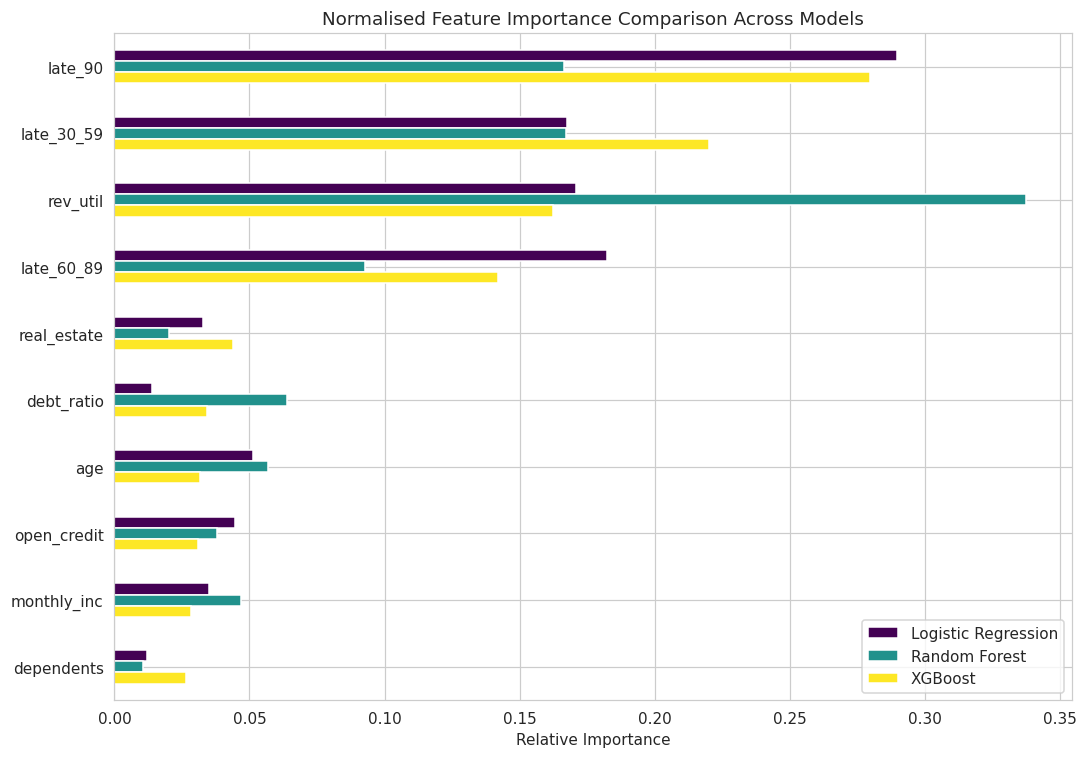

In [34]:
# visualising the normalised feature importance across all three models
importance_df.plot(kind="barh", figsize=(10, 7), colormap="viridis")
plt.title("Normalised Feature Importance Comparison Across Models")
plt.xlabel("Relative Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 13. Global Explainability Using SHAP

In [35]:
# building a shap explainer suited to the best performing model
if best_model_name == "Logistic Regression":
    explainer = shap.LinearExplainer(best_model, X_train_explain)
else:
    explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_test_explain)

# handling the case where shap returns a list of arrays for classification
if isinstance(shap_values, list):
    shap_values = shap_values[1]

# handling the case where shap returns a single 3d array for classification
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP values are computed for", X_test_explain.shape[0], "test records")


SHAP values are computed for 3343 test records


### 13.1 SHAP Summary Plot

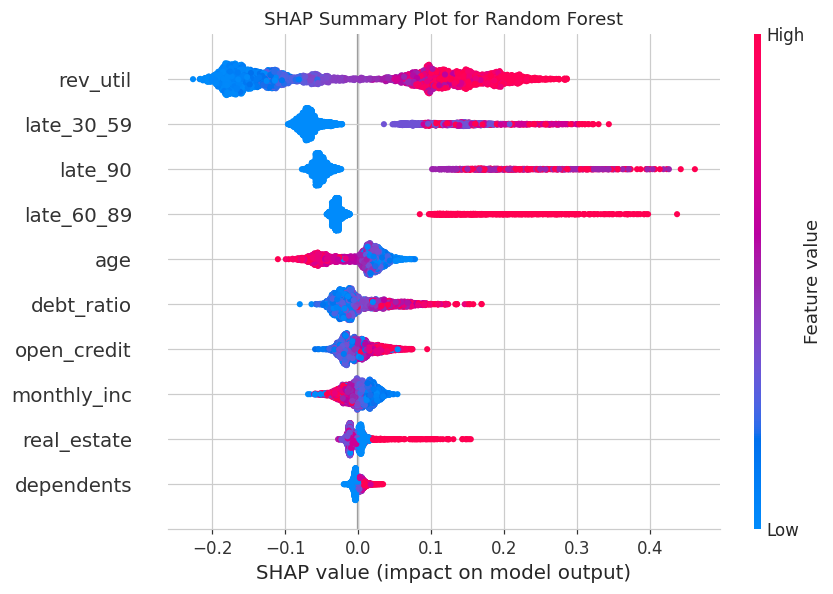

In [36]:
# plotting the shap summary plot to show feature impact and direction across all predictions
shap.summary_plot(shap_values, X_test_explain, show=False)
plt.title("SHAP Summary Plot for " + best_model_name)
plt.tight_layout()
plt.show()


### 13.2 SHAP Feature Importance Bar Chart

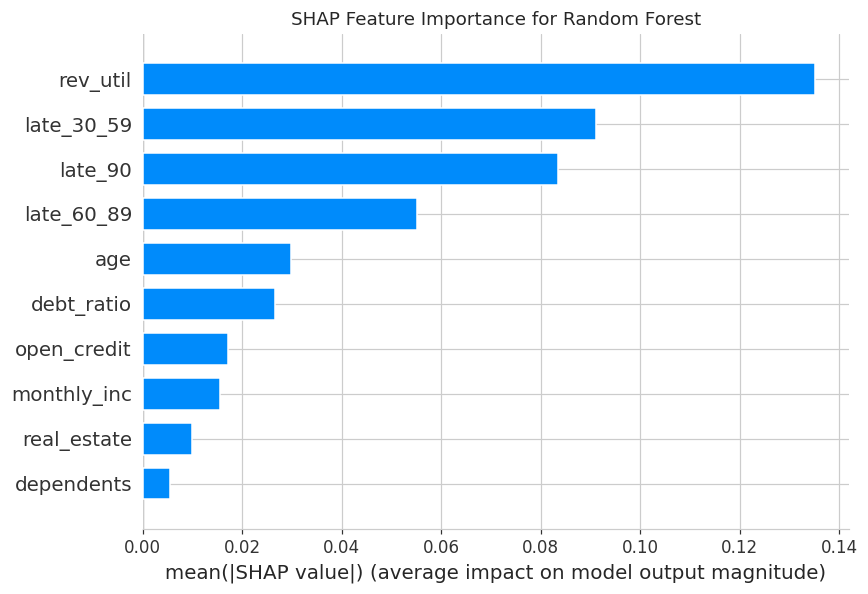

In [37]:
# plotting the shap based mean absolute feature importance bar chart
shap.summary_plot(shap_values, X_test_explain, plot_type="bar", show=False)
plt.title("SHAP Feature Importance for " + best_model_name)
plt.tight_layout()
plt.show()


## 14. Local Prediction Explanations Using SHAP

In [38]:
# selecting one correctly identified high risk borrower and one low risk borrower for local explanation
test_predictions = best_model.predict(X_test_explain)
high_risk_index = X_test_explain[(test_predictions == 1) & (y_test.values == 1)].index[0]
low_risk_index = X_test_explain[(test_predictions == 0) & (y_test.values == 0)].index[0]

high_risk_position = X_test_explain.index.get_loc(high_risk_index)
low_risk_position = X_test_explain.index.get_loc(low_risk_index)

print("High risk borrower selected at index:", high_risk_index)
print("Low risk borrower selected at index:", low_risk_index)


High risk borrower selected at index: 8954
Low risk borrower selected at index: 1636


In [39]:
# building the shap explanation object needed for the waterfall plot
explanation = explainer(X_test_explain)
if len(explanation.shape) == 3:
    explanation = explanation[:, :, 1]


### 14.1 SHAP Waterfall Plot for a High Risk Borrower

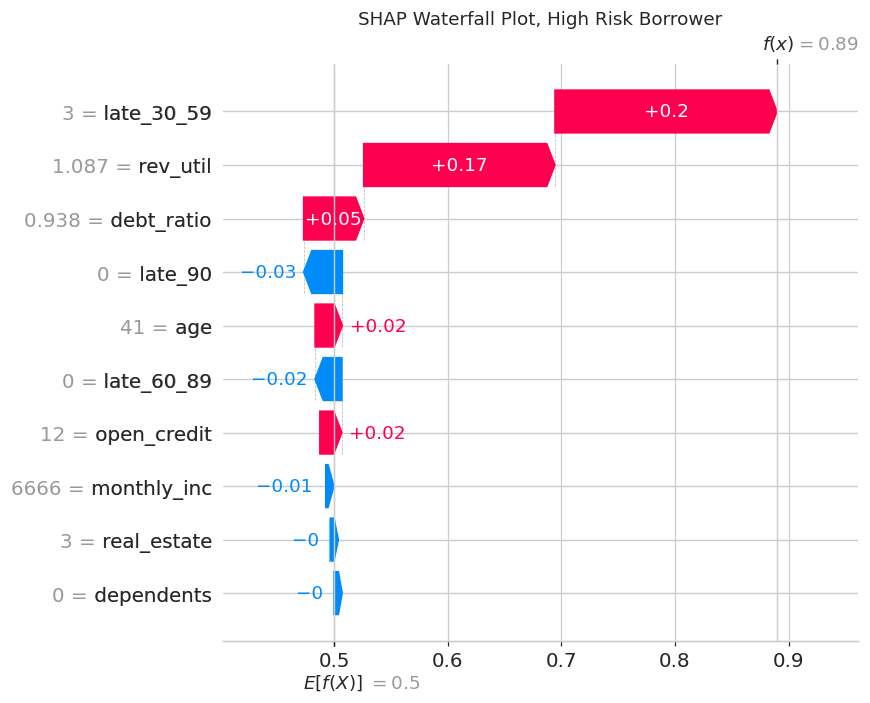

In [40]:
# plotting the shap waterfall plot for the selected high risk borrower
shap.plots.waterfall(explanation[high_risk_position], show=False)
plt.title("SHAP Waterfall Plot, High Risk Borrower")
plt.tight_layout()
plt.show()


### 14.2 SHAP Waterfall Plot for a Low Risk Borrower

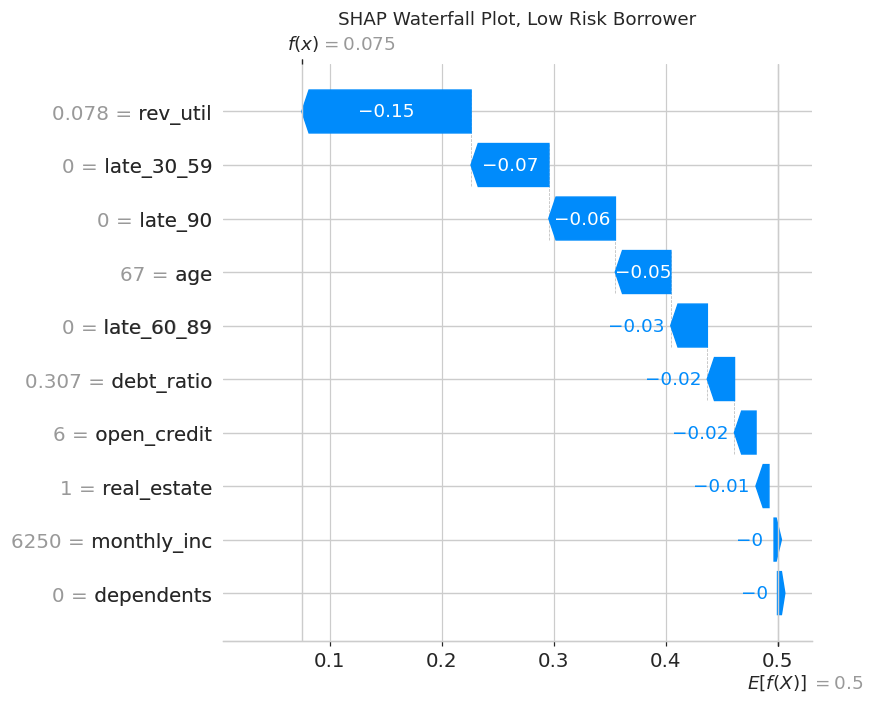

In [41]:
# plotting the shap waterfall plot for the selected low risk borrower
shap.plots.waterfall(explanation[low_risk_position], show=False)
plt.title("SHAP Waterfall Plot, Low Risk Borrower")
plt.tight_layout()
plt.show()


## 15. Individual Prediction Explanations Using LIME

In [42]:
# building a lime tabular explainer using the training data distribution
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train_explain),
    feature_names=feature_names,
    class_names=["No Delinquency", "Delinquency"],
    mode="classification",
    random_state=RANDOM_STATE
)
print("LIME explainer is ready")


LIME explainer is ready


### 15.1 LIME Explanation for the High Risk Borrower

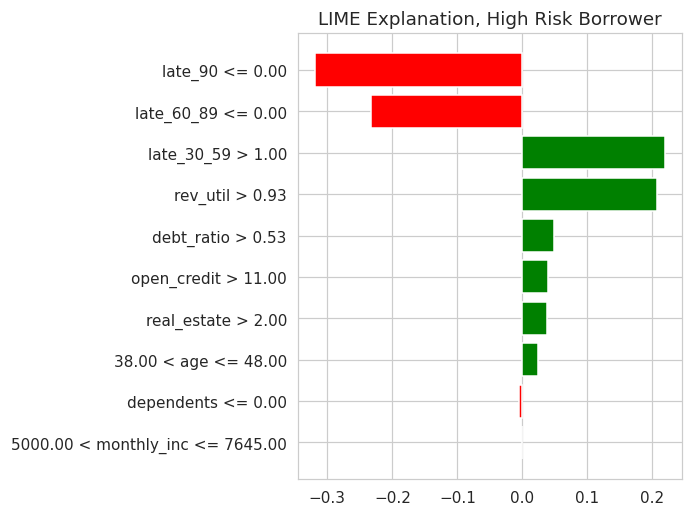

In [43]:
# generating a lime explanation for the high risk borrower
lime_exp_high = lime_explainer.explain_instance(
    data_row=X_test_explain.loc[high_risk_index].values,
    predict_fn=best_model.predict_proba,
    num_features=10
)

lime_exp_high.as_pyplot_figure()
plt.title("LIME Explanation, High Risk Borrower")
plt.tight_layout()
plt.show()


### 15.2 LIME Explanation for the Low Risk Borrower

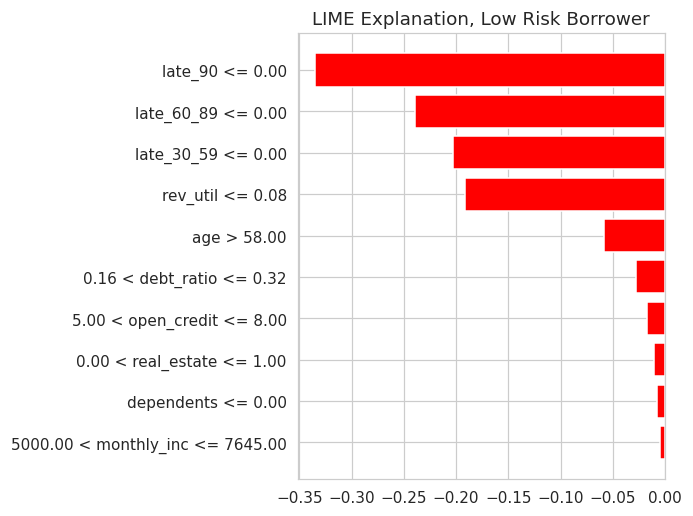

In [44]:
# generating a lime explanation for the low risk borrower
lime_exp_low = lime_explainer.explain_instance(
    data_row=X_test_explain.loc[low_risk_index].values,
    predict_fn=best_model.predict_proba,
    num_features=10
)

lime_exp_low.as_pyplot_figure()
plt.title("LIME Explanation, Low Risk Borrower")
plt.tight_layout()
plt.show()


In [45]:
# displaying the lime explanation for the high risk borrower as a readable list of feature contributions
print("LIME feature contributions for the high risk borrower")
for feature, weight in lime_exp_high.as_list():
    print(f"{feature}: {weight:.4f}")


LIME feature contributions for the high risk borrower
late_90 <= 0.00: -0.3189
late_60_89 <= 0.00: -0.2325
late_30_59 > 1.00: 0.2187
rev_util > 0.93: 0.2065
debt_ratio > 0.53: 0.0479
open_credit > 11.00: 0.0394
real_estate > 2.00: 0.0386
38.00 < age <= 48.00: 0.0237
dependents <= 0.00: -0.0047
5000.00 < monthly_inc <= 7645.00: 0.0000


In [46]:
# displaying the lime explanation for the low risk borrower as a readable list of feature contributions
print("LIME feature contributions for the low risk borrower")
for feature, weight in lime_exp_low.as_list():
    print(f"{feature}: {weight:.4f}")


LIME feature contributions for the low risk borrower
late_90 <= 0.00: -0.3349
late_60_89 <= 0.00: -0.2392
late_30_59 <= 0.00: -0.2027
rev_util <= 0.08: -0.1911
age > 58.00: -0.0588
0.16 < debt_ratio <= 0.32: -0.0282
5.00 < open_credit <= 8.00: -0.0173
0.00 < real_estate <= 1.00: -0.0110
dependents <= 0.00: -0.0077
5000.00 < monthly_inc <= 7645.00: -0.0049


## 16. Comparative Analysis of SHAP and LIME

In [47]:
# comparing the top five globally important features identified by shap against the model native importance
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)

comparison_table = pd.DataFrame({
    "SHAP Importance": shap_importance,
    "Native Model Importance": importance_df[best_model_name]
}).sort_values("SHAP Importance", ascending=False)

comparison_table.head(10)


,SHAP Importance,Native Model Importance
rev_util,0.135148,0.337522
late_30_59,0.091014,0.167107
late_90,0.083466,0.166268
late_60_89,0.055174,0.092713
age,0.029729,0.056743
debt_ratio,0.026536,0.063834
open_credit,0.017103,0.038032
monthly_inc,0.015563,0.046756
real_estate,0.009900,0.020296
dependents,0.005419,0.010730


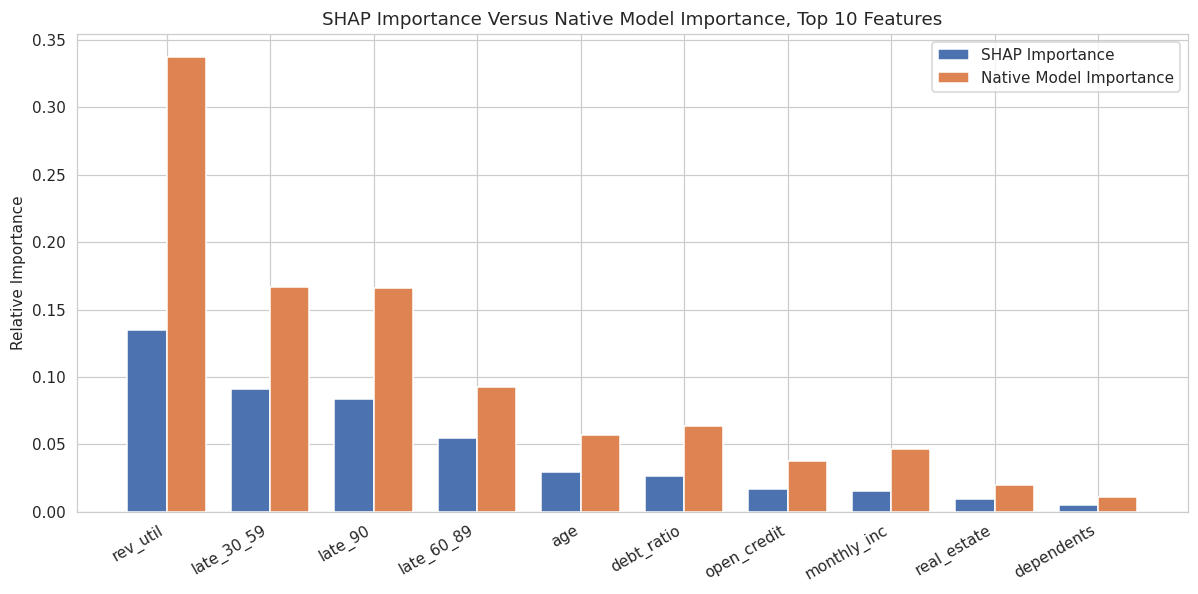

In [48]:
# visualising the agreement between shap importance and the native model importance for the top features
top_features = comparison_table.head(10)

fig, ax1 = plt.subplots(figsize=(11, 5.5))
x_pos = np.arange(len(top_features))
width = 0.38

ax1.bar(x_pos - width/2, top_features["SHAP Importance"], width=width, label="SHAP Importance", color="#4C72B0")
ax1.bar(x_pos + width/2, top_features["Native Model Importance"], width=width, label="Native Model Importance", color="#DD8452")

ax1.set_xticks(x_pos)
ax1.set_xticklabels(top_features.index, rotation=30, ha="right")
ax1.set_title("SHAP Importance Versus Native Model Importance, Top 10 Features")
ax1.set_ylabel("Relative Importance")
ax1.legend()

plt.tight_layout()
plt.show()


The SHAP summary and bar plots highlight the global drivers of delinquency risk across the entire test population, with revolving utilisation, the count of 30 to 59 day late payments, and the count of 90 day late payments consistently ranking as the strongest predictors, which aligns closely with the native feature importance produced by the underlying model. LIME complements this global picture by explaining single borrower decisions in isolation, fitting a locally faithful linear surrogate around each prediction. For the high risk borrower, both SHAP and LIME agree that high revolving utilisation and a history of late payments push the prediction toward delinquency, whereas for the low risk borrower both methods agree that low utilisation and a clean repayment history push the prediction toward non delinquency. The main practical difference is that SHAP is grounded in cooperative game theory and gives globally consistent attributions that sum exactly to the model output, while LIME approximates the decision boundary locally and can be slightly less stable if rerun with a different random sample, which is a known tradeoff between the two techniques when used for regulatory grade model explanations.

## 17. Conclusion

This project implemented and compared three classification models for predicting serious credit delinquency within two years, namely Logistic Regression, Random Forest, and XGBoost, evaluated using accuracy, precision, recall, F1 score, ROC AUC, and confusion matrices. The best performing model was further interpreted using SHAP for global and local explainability and LIME for individual borrower level explanations, demonstrating that strong predictive performance and model transparency are not mutually exclusive and can be combined to build trustworthy, regulation friendly credit risk assessment systems.